# Quickstart VLM + ventilation

Self-contained demo of the VLM + ventilation coupling algorithm.
We build the strut from Harwood, C. M., Young, Y. L., & Ceccio, S. L. experiments from ([Ventilated cavities on a surface-piercing
hydrofoil at moderate Froude numbers : cavity formation, elimination and stability](https://doi.org/10.1017/jfm.2016.373)).
This case is used for demonstration because of its simplicity and validation data but more complex geometries can be done. 

Run from the **repo root** (`src/` imports assume it).

In [1]:
import sys

sys.path.append(("./src/"))

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator


from VLMSurface import VLMSurface
from VLMSolver import VLMSolver
from Utilities import load_csv, chord_fn

plt.rcParams['font.family'] = 'serif'
plt.rcParams['font.serif'] = ['Times New Roman']
plt.rcParams['mathtext.fontset'] = 'stix'

## First simulation
This code builds the vertical strut and run both a wetted and ventilated simulation for a given Froude number

In [2]:
# ---- case definition : Harwood's test case : rectangular strut with an immersed aspect ratio of 1 ----
B      = 0.279                      # span [m]
AR     = 1                          # immersed aspect ratio
FROUDE = 3.5                        # depth-based Froude number
U      = FROUDE * np.sqrt(9.81 * B) # freestream velocity [m/s]
FREE   = "antisymmetric"            # free-surface boundary condition
N, M   = 10, 10                     # spanwise x chordwise panels
LEEWAY = 10                         # leeway angle [deg]

# ---- build the strut ----
strut = VLMSurface(boundary=FREE,
                    shedding="right",
                    b=B,
                    c=chord_fn(N + 1, AR, B, False, False, "rectangular"), 
                    beta=np.deg2rad(LEEWAY),
                    n=N, m=M, )

print(f"U = {U:.2f} m/s, mesh = {N}x{M}")

# ---- run the solver ----
vlm = VLMSolver([strut], np.array([U, 0, 0]), FREE)     # initialize the solver
vlm._time_sim()                                         # run the simulation            
vlm._kuttas_loads()                                     # compute the loads

print("Wetted flow CL     = ", strut.CL)

# ---- run the ventilation algorithm ----
vlm._ventilation()                                  

print("Ventilated flow CL = ", strut.CL)



U = 5.79 m/s, mesh = 10x10
Wetted flow CL     =  0.26494742131896376
Ventilated flow CL =  0.15833381317558834


## Comparison with Harwood's data

Run the previously shown simulation for different angles of attack $\alpha$ and depth-based Froude number $Fn_h$ by adjusting the leeway angle and the freestream velocity. 

In [3]:
Fn_h   = np.linspace(1.5, 3.5, 3)
U      = Fn_h * np.sqrt(9.81 * B)
LEEWAY = np.linspace(2.5,30,12)
CL_dic = {}

def strut_sim(leeway, u):
    strut = VLMSurface(boundary=FREE,
                    shedding="right",
                    b=B,
                    c=chord_fn(N + 1, AR, B, False, True, "rectangular"), 
                    beta=np.deg2rad(leeway),
                    n=N, m=M, space=True)
    vlm = VLMSolver([strut], np.array([u, 0, 0]), FREE)
    vlm._ventilation() 
    return strut.CL

for i, u in enumerate(U):
    CL = []
    for leeway in LEEWAY :  
        CL.append(strut_sim(leeway, u))
    CL_dic[Fn_h[i]] = CL        

Generate the plot to compare the results against the experimental data :

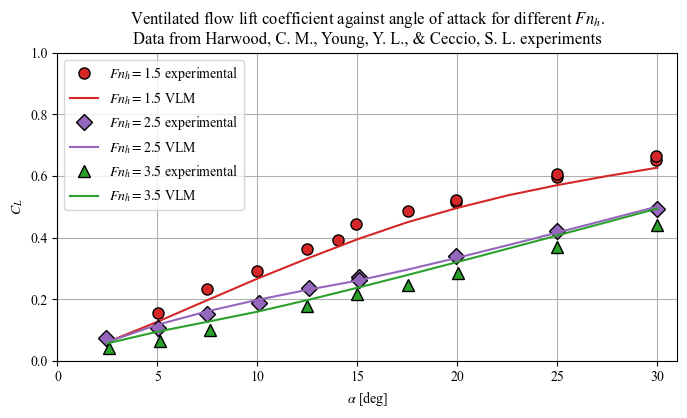

In [4]:
fig, ax = plt.subplots(figsize=(8, 4))

x, y = load_csv("data/cl_ar1_fn15_v.csv")
ax.plot(x,y,"o", ms=8, markerfacecolor='C3', markeredgecolor='black', label=r'$Fn_{h}=1.5$'+" experimental")
ax.plot(LEEWAY, CL_dic[1.5], color='C3', label=r'$Fn_{h}=1.5$'+" VLM")

x, y = load_csv("data/cl_ar1_fn25_v.csv")
ax.plot(x,y,"D", ms=8, markerfacecolor='C4', markeredgecolor='black', label=r'$Fn_{h}=2.5$'+" experimental")
ax.plot(LEEWAY, CL_dic[2.5], color='C4', label=r'$Fn_{h}=2.5$'+" VLM")

x, y = load_csv("data/cl_ar1_fn35_v.csv")
ax.plot(x,y,"^", ms=8, markerfacecolor='C2', markeredgecolor='black', label=r'$Fn_{h}=3.5$'+" experimental")
ax.plot(LEEWAY, CL_dic[3.5], color='C2', label=r'$Fn_{h}=3.5$'+" VLM")

ax.grid(True)
ax.set_xlim(0,31)
ax.set_ylim(0,1) 
ax.xaxis.set_major_locator(MultipleLocator(5))
ax.yaxis.set_major_locator(MultipleLocator(0.2))

ax.set_title("Ventilated flow lift coefficient against angle of attack for different "+r'$Fn_h$'+".\nData from Harwood, C. M., Young, Y. L., & Ceccio, S. L. experiments")
plt.xlabel(r'$\alpha$'+" [deg]", )
plt.ylabel(r'$C_L$')

plt.legend()
plt.show()